# 📱 삼성 CS 티케팅 & 에스컬레이션 멀티 에이전트 시스템
## Day 3 Mini Project

---

### 🎯 프로젝트 목표

스마트폰 에러 화면 이미지가 접수되면 AI 파이프라인이 자동으로:
1. 이미지에서 에러 증상을 추출하고
2. 사내 CS 매뉴얼에서 해결책을 검색한 뒤
3. **매뉴얼에 해결책이 있으면** → 고객에게 안내 메시지 생성
4. **매뉴얼에 없는 에러면** → CS 티켓 자동 생성 (우선순위 + 담당팀 분류)

### 🏗️ 파이프라인 아키텍처

```
📱 에러 이미지
     │
     ▼
[node_vision]        ← Qwen3-VL-2B: 이미지 → 에러 증상 텍스트
     │
     ▼
[node_rag]           ← ChromaDB: 증상 → (매뉴얼 내용, 유사도 거리 점수)
     │
     ▼
[route_by_score]     ← 조건부 엣지: 유사도 점수 기반 분기
  ├── 점수 ≤ 임계값 (매뉴얼 있음) ──→ [node_guide]  → 해결 안내 생성 (Gemma3n)
  └── 점수 > 임계값 (매뉴얼 없음) ──→ [node_ticket] → CS 티켓 JSON 생성 (Gemma3n)
                                                             │
                                                             ▼
                                                            END
```

### 📚 문제별 채점 항목

| 문제 | 빈칸 ID | 핵심 개념 |
|------|---------|-----------|
| Problem 1 | P1 | VLM 추론, messages 구조 |
| Problem 2 | P2-1, P2-2, P2-3 | RAG, chunk_size, 유사도 임계값 |
| Problem 3 | P3-1, P3-2 | Gemma 3n on-device LLM, ChatOllama 인스턴스 만들기|
| Problem 4 | P4-1 ~ P4-5 | LangGraph 조건부 엣지, 멀티 경로 그래프 |

> 각 문제의 `# YOUR CODE HERE` 부분을 완성하세요.

In [ ]:
######################################################################################
# Authored by Andrew Wan Ju Kang, Ph.D.
# soarhigh0714@gmail.com
# Do not re-distribute.
######################################################################################

---
## 🛠️ Section 0: 환경 설정

In [ ]:
# 필수 패키지 설치 여부 확인
import importlib

required = [
    "torch", "transformers", "PIL",
    "langchain", "langchain_chroma", "langchain_openai", "langchain_ollama",
    "langgraph", "chromadb", "ollama"
]
missing = []
for pkg in required:
    try:
        importlib.import_module(pkg)
        print(f"  ✅ {pkg}")
    except ImportError:
        print(f"  ❌ {pkg} — 설치 필요")
        missing.append(pkg)

if missing:
    print(f"\n⚠️  누락 패키지: {missing}")
else:
    print("\n🎉 모든 패키지 준비 완료")

In [ ]:
import os, torch, nest_asyncio
from dotenv import load_dotenv

nest_asyncio.apply()
load_dotenv()

# 프록시 / OpenAI API 환경 변수 처리
proxy_token = os.environ.get("PROXY_TOKEN") or os.environ.get("OPENAI_API_KEY")
proxy_url   = os.environ.get("PROXY_URL")   or os.environ.get("OPENAI_API_BASE")
if proxy_token: os.environ["OPENAI_API_KEY"]  = proxy_token
if proxy_url:   os.environ["OPENAI_API_BASE"] = proxy_url

print("OPENAI_API_KEY 설정:", bool(os.environ.get("OPENAI_API_KEY")))
print("OPENAI_API_BASE 설정:", bool(os.environ.get("OPENAI_API_BASE")))
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU 전용'}")

In [ ]:
# Ollama 서버 및 모델 목록 확인
import subprocess

try:
    result = subprocess.run(["ollama", "list"], capture_output=True, text=True, timeout=5)
    print("Ollama 사용 가능 모델:")
    print(result.stdout if result.stdout.strip() else "  (다운로드된 모델 없음)")
    OLLAMA_AVAILABLE = True
except Exception as e:
    print(f"⚠️  Ollama 연결 실패: {e}")
    OLLAMA_AVAILABLE = False

---
## 💡 Problem 1: VLM — 에러 화면 이미지 분석
**연계 모듈: M6 (Multi-Modal SLM), M9 (Visual Understanding)**

### 개념 설명

**Vision Language Model (VLM)** 은 이미지와 텍스트를 동시에 처리하는 멀티모달 모델입니다.

```
이미지 입력 ──→ [Vision Encoder (ViT)] ──→ 이미지 임베딩
                                                  │
텍스트 입력 ──→ [Text Tokenizer]       ──→ 텍스트 임베딩
                                                  │
                          [Language Model (LM)] ──→ 텍스트 출력
```

### dtype 선택 기준

| dtype | 메모리/파라미터 | 권장 환경 |
|-------|--------------|-----------|
| `float32` | 4 bytes | 구형 GPU |
| `float16` | 2 bytes | 구형 NVIDIA (Volta 이전) |
| **`bfloat16`** | **2 bytes** | **Turing 이상** |

`bfloat16`은 `float32`와 동일한 지수 범위를 가져 학습/추론 안정성이 높습니다.

In [ ]:
import requests
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"

INFERENCE_DTYPE = torch.bfloat16

print(f"⏳ Qwen3-VL-2B 로딩 중 (dtype={INFERENCE_DTYPE}) ...")
vlm_model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    dtype=INFERENCE_DTYPE,
    device_map="auto"
)
vlm_processor = AutoProcessor.from_pretrained(MODEL_ID)
print(f"✅ 모델 로드 완료 — 실제 dtype: {vlm_model.dtype}")

In [ ]:
def extract_error_from_image(image_source: str) -> str:
    """
    스마트폰 에러 화면 이미지를 분석하여 에러 증상 텍스트를 추출합니다.
    URL 또는 로컬 파일 경로를 모두 지원합니다.
    """
    if image_source.startswith("http"):
        image = Image.open(requests.get(image_source, stream=True).raw).convert("RGB")
    else:
        image = Image.open(image_source).convert("RGB")

    # =========================================================================
    # [P1] VLM에 전달할 messages 리스트를 완성하세요.
    #   - role: "user"
    #   - content: 두 개의 딕셔너리 (image와 text)    
    # =========================================================================
    messages = [
        {
            "role": "user",
            "content": [
                # YOUR CODE HERE
                # YOUR CODE HERE
            ]
        }
    ]

    prompt = vlm_processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = vlm_processor(text=prompt, images=[image], return_tensors="pt").to(vlm_model.device)

    MAX_TOKENS = 80
    with torch.inference_mode():
        generated_ids = vlm_model.generate(
            **inputs,
            max_new_tokens=MAX_TOKENS,
            repetition_penalty=1.2,
            do_sample=False
        )

    full_text = vlm_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]

    # assistant 파트만 추출
    if "assistant" in full_text.lower():
        answer = full_text.lower().split("assistant")[-1].strip()
    else:
        answer = full_text.strip()

    return answer if answer else "에러 메시지를 감지하지 못했습니다."


# --- 동작 확인 ---
TEST_IMAGE = "/home/user/MultiAgents/Day_3/Projects/nospace.jpg"
print("⏳ VLM 테스트 실행 중...")
test_output = extract_error_from_image(TEST_IMAGE)
print("VLM 출력:", test_output[:200])

---
## 💡 Problem 2: RAG — 유사도 점수 기반 매뉴얼 검색
**연계 모듈: M3 (RAG Retrieval Layer), M4 (Advanced RAG)**

### 개념 설명

이 프로젝트의 RAG는 단순히 매뉴얼을 검색하는 것을 넘어, **유사도 거리 점수**를 함께 반환합니다.
이 점수가 이후 LangGraph의 조건부 엣지에서 경로 분기의 근거가 됩니다.

```
증상 텍스트
  └──→ [Embedding Model]             → 질의 벡터
  └──→ [ChromaDB.similarity_search_with_score] → (문서, L2 거리 점수)

L2 거리 점수 해석:
  0.0 ~ 임계값  → 유사도 높음 (매뉴얼 있음) → 안내 생성 경로
  임계값 초과   → 유사도 낮음 (매뉴얼 없음) → CS 티켓 생성 경로
```

### chunk_size 선택 기준

청크 하나에 **증상 + 해결책 + 주의** 항목이 모두 들어가야 합니다.
매뉴얼 항목 하나의 길이를 확인한 뒤 적절한 크기를 선택하세요.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma

# CS 매뉴얼 원문 — 저장공간(STOR) 항목은 의도적으로 제외
# → nospace.jpg는 매뉴얼 미등재 에러로 처리되어 CS 티켓 경로로 분기됩니다.
DEVICE_MANUAL = """
[삼성 스마트폰 CS 매뉴얼 v3.0]

1. 증상: 화면에 '온도가 너무 높습니다' 경고 (Error Code: TEMP-01)
   원인: 고온 환경, 집중 앱 사용, 충전 중 과부하
   해결책: 기기 전원을 끄고 서늘한 곳에서 15분 이상 방치하세요. 백그라운드 앱을 모두 종료하세요.
   주의: 충전기를 즉시 분리하고 직사광선 노출을 피하세요.

2. 증상: 'USIM 카드를 인식할 수 없습니다' (Error Code: SIM-01)
   원인: USIM 단자 이물질, 부정확한 삽입, 칩 손상
   해결책: 트레이 핀으로 USIM을 분리한 후 금속 단자를 마른 천으로 닦고 재삽입하세요.
   주의: 핀을 이어폰 잭에 삽입하지 마세요.

3. 증상: Wi-Fi 연결 불가 / '인터넷 연결 없음' (Error Code: NET-03)
   원인: 네트워크 설정 오류, DNS 캐시 손상, 라우터 호환성 문제
   해결책: 설정 > 일반 > 재설정 > 네트워크 설정 초기화 후 라우터를 재부팅하세요.
   주의: 초기화 시 저장된 Wi-Fi 비밀번호가 모두 삭제됩니다.

4. 증상: 화면이 켜지지 않음 / 검은 화면 (Error Code: DISP-01)
   원인: 소프트웨어 크래시, 배터리 방전, 디스플레이 드라이버 오류
   해결책: 전원 버튼 + 볼륨 다운 버튼을 동시에 10초간 눌러 강제 재시작하세요.
   주의: 데이터 손실 없이 재시작됩니다. 반복 발생 시 서비스 센터 방문이 필요합니다.
"""

# =============================================================================
# [P2-1] 텍스트 분할기 파라미터를 설정하세요.
#        매뉴얼 항목 하나(증상 + 원인 + 해결책 + 주의)가 청크 안에 온전히 들어가려면
#        chunk_size를 얼마로 설정해야 할까요?
#        필요에 따라 chunk_overlap을 바꾸셔도 됩니다.
# =============================================================================
splitter = RecursiveCharacterTextSplitter(
    chunk_size= , # YOUR CODE HERE
    chunk_overlap=50
)
chunks = splitter.split_text(DEVICE_MANUAL)

print(f"총 {len(chunks)}개 청크 생성됨")
for i, c in enumerate(chunks):
    print(f"  Chunk {i+1} ({len(c)}자): {c[:80]}...")

Chroma(collection_name="samsung_cs_manual_v3", embedding_function=None).delete_collection()

vector_store = Chroma(
    collection_name="samsung_cs_manual_v3",
    embedding_function=OpenAIEmbeddings(
        model="text-embedding-3-small",
        openai_api_key=os.environ.get("OPENAI_API_KEY"),
        openai_api_base=os.environ.get("OPENAI_API_BASE")
    )
)
vector_store.add_texts(texts=chunks)
print("\n✅ 벡터스토어 구축 완료")

In [ ]:
# ── 임계값 캘리브레이션 셀 (채점 없음, 이해용) ──────────────────────────────
# similarity_search_with_score 는 L2 거리를 반환합니다.
# 값이 낮을수록 유사도가 높습니다.

calibration_queries = [
    "온도가 너무 높습니다",       # → TEMP-01 (매뉴얼 있음)
    "USIM 카드를 인식할 수 없습니다",  # → SIM-01 (매뉴얼 있음)
    "Wi-Fi 연결이 되지 않습니다",  # → NET-03 (매뉴얼 있음)
    "저장공간이 부족합니다",       # → 매뉴얼 없음 (임계값 초과해야 함)
]

print("=== 유사도 거리 점수 캘리브레이션 ===")
print(f"{'질의':<30} {'1위 점수':>10}  {'1위 청크 미리보기'}")
print("-" * 80)
for q in calibration_queries:
    results = vector_store.similarity_search_with_score(q, k=1)
    if results:
        doc, score = results[0]
        print(f"{q:<30} {score:>10.4f}  {doc.page_content[:40]}...")
    else:
        print(f"{q:<30} {'N/A':>10}")

In [ ]:
# =============================================================================
# [P2-2] similarity_search_with_score 의 k 값을 설정하세요.
#        트러블슈팅은 가장 관련성 높은 항목 하나로 충분합니다.
#
# [P2-3] SCORE_THRESHOLD 값을 설정하세요.
#        위 캘리브레이션 결과를 참고하여 '매뉴얼 있음'과 '매뉴얼 없음'을
#        구분할 수 있는 L2 거리 임계값을 정하세요.
# =============================================================================
RETRIEVE_K = # YOUR CODE HERE
SCORE_THRESHOLD = # YOUR CODE HERE  # 캘리브레이션 결과를 참고하세요


def retrieve_with_score(error_symptom: str) -> tuple[str, float]:
    """
    에러 증상으로 매뉴얼을 검색하고 (매뉴얼 내용, L2 거리 점수)를 반환합니다.
    점수가 낮을수록 유사도가 높습니다.
    """
    results = vector_store.similarity_search_with_score(error_symptom, k=RETRIEVE_K)
    if not results:
        return "매뉴얼 검색 결과 없음", 999.0
    doc, score = results[0]
    return doc.page_content, score


# --- 동작 확인 ---
test_manual, test_score = retrieve_with_score("Wi-Fi 연결이 되지 않습니다")
print(f"검색 결과 점수: {test_score:.4f}")
print(f"검색된 매뉴얼: {test_manual[:100]}...")
print(f"\n임계값({SCORE_THRESHOLD}) 기준: {'✅ 매뉴얼 있음 → 안내 경로' if test_score <= SCORE_THRESHOLD else '🎫 매뉴얼 없음 → 티켓 경로'}")

---
## 💡 Problem 3: On-Device LLM — Gemma 3n 응답 생성
**연계 모듈: M5 (Domain SLM), M8 (On-device 최적화 & 경량화)**

### Gemma 3n 소개

Google DeepMind가 2025년 출시한 **Gemma 3n**은 경량 텍스트 모델입니다.
- E2B: 2B 파라미터, 32K 컨텍스트, 텍스트 처리
- Ollama 지원

최초 실행 시 Ollama 모델 다운로드가 수 분 소요됩니다 (네트워크 상황에 따라 1분~5분 예상)

In [ ]:
from langchain_ollama import ChatOllama
from langchain_openai import ChatOpenAI
from langchain_core.prompts import PromptTemplate
import json, re


# =============================================================================
# [P3-1] On-device LLM 모델명을 설정하세요.
#        Gemma 3n 모델명을 입력하세요.
#        "gemma3n:e2b"
# [P3-2] ChatOllama 인스턴스를 만드세요.
#        이전 실습 자료를 참고하여 적절한 초기값을 설정하세요.
#        최소 model, temperature, num_predict 세가지는 입력해주세요. (나머지 인자들은 선택사항)
# =============================================================================


import ollama
MODEL = # YOUR CODE HERE   # 예: "gemma3n:e2b"
try:
    ollama.show(MODEL)
except Exception:
    ollama.pull(MODEL)


if OLLAMA_AVAILABLE:
    llm = # YOUR CODE HERE
    # ...
    # ...
    LLM_BACKEND = f"ollama ({MODEL})"
    print("✅ Gemma 3n 온디바이스 모델 사용")
else:
    llm = ChatOpenAI(
        model="gpt-4o-mini",
        openai_api_key=os.environ.get("OPENAI_API_KEY"),
        openai_api_base=os.environ.get("OPENAI_API_BASE"),
        temperature=0.1,
    )
    LLM_BACKEND = "proxy (gpt-4o-mini)"
    print("⚠️  Ollama 불가 — OpenAI 프록시 폴백")




In [ ]:
# ── 안내 메시지 생성 체인 ──────────────────────────────────────────────────
guide_prompt = PromptTemplate.from_template(
    "당신은 친절한 삼성전자 고객서비스 어시스턴트입니다.\n"
    "고객 에러 증상: {symptom}\n"
    "매뉴얼 내용: {manual}\n\n"
    "위 정보를 바탕으로 해결 방법을 쉽고 친절하게 3줄 이내로 안내하세요.\n\n"
    "답변:"
)
guide_chain = guide_prompt | llm


def generate_guide(symptom: str, manual: str) -> str:
    """매뉴얼 기반 고객 안내 메시지를 생성합니다."""
    response = guide_chain.invoke({"symptom": symptom, "manual": manual})
    return response.content.strip()


# ── CS 티켓 생성 체인 ──────────────────────────────────────────────────────
ticket_prompt = PromptTemplate.from_template(
    "당신은 삼성전자 CS 티케팅 시스템입니다.\n"
    "매뉴얼에 등록되지 않은 에러가 접수되었습니다. CS 티켓을 생성하세요.\n"
    "에러 증상: {symptom}\n\n"
    "반드시 아래 JSON 형식으로만 응답하세요. 다른 텍스트 없이 JSON만 출력하세요:\n"
    "{{\n"
    "  \"priority\": \"HIGH 또는 MEDIUM 또는 LOW\",\n"
    "  \"team\": \"하드웨어팀 또는 소프트웨어팀 또는 네트워크팀 또는 스토리지팀\",\n"
    "  \"summary\": \"증상 한 줄 요약 (30자 이내)\",\n"
    "  \"recommended_action\": \"1차 조치 방향 (50자 이내)\"\n"
    "}}\n\n"
    "JSON:"
)
ticket_chain = ticket_prompt | llm


def generate_ticket(symptom: str) -> dict:
    """매뉴얼 미등재 에러에 대한 CS 티켓 딕셔너리를 생성합니다."""
    import uuid, datetime
    response = ticket_chain.invoke({"symptom": symptom})
    raw = response.content.strip()

    # JSON 파싱 — LLM 출력에서 JSON 블록 추출
    match = re.search(r'\{.*\}', raw, re.DOTALL)
    if match:
        try:
            ticket_data = json.loads(match.group())
        except json.JSONDecodeError:
            ticket_data = {"priority": "MEDIUM", "team": "CS팀",
                           "summary": raw[:30], "recommended_action": "전문가 검토 필요"}
    else:
        ticket_data = {"priority": "MEDIUM", "team": "CS팀",
                       "summary": raw[:30], "recommended_action": "전문가 검토 필요"}

    # 메타데이터 추가
    ticket_data["ticket_id"] = f"TKT-{uuid.uuid4().hex[:6].upper()}"
    ticket_data["created_at"] = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
    ticket_data["symptom"]    = symptom
    return ticket_data


# --- 동작 확인 ---
print("⏳ 안내 메시지 테스트...")
guide_result = generate_guide(
    symptom="Wi-Fi 연결이 되지 않습니다",
    manual="설정 > 일반 > 재설정 > 네트워크 설정 초기화 후 라우터를 재부팅하세요."
)
print("안내 메시지:", guide_result[:200])

print("\n⏳ CS 티켓 생성 테스트...")
ticket_result = generate_ticket("저장공간이 부족합니다")
print("생성된 티켓:")
for k, v in ticket_result.items():
    print(f"  {k}: {v}")

---
## 💡 Problem 4: LangGraph — 조건부 엣지 멀티 경로 워크플로우
**연계 모듈: M1 (Agentic AI), M2 (Multi-Agent Workflow)**

### 조건부 엣지(Conditional Edge)란?

기존 `add_edge`는 **항상 같은 노드로** 이동합니다.
`add_conditional_edges`는 **라우팅 함수의 반환값에 따라 다른 노드로** 분기합니다.

```python
# 일반 엣지: rag → generate (항상)
workflow.add_edge("rag", "generate")

# 조건부 엣지: rag → guide 또는 rag → ticket (라우팅 함수 결과에 따라)
workflow.add_conditional_edges(
    "rag",                              # 출발 노드
    route_by_score,                     # 라우팅 함수
    {"guide": "guide", "ticket": "ticket"}  # 반환값 → 도착 노드 매핑
)
```

### 이 프로젝트의 State

```python
class TroubleshootingState(TypedDict):
    image_url:        str    # 입력: 에러 이미지 경로
    error_symptom:    str    # Node 1 출력: VLM 추출 증상
    retrieved_manual: str    # Node 2 출력: RAG 검색 매뉴얼
    rag_score:        float  # Node 2 출력: L2 유사도 거리 점수 ← 신규
    final_answer:     str    # Node 3 출력: 안내 메시지 또는 티켓 JSON
```

In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

# ── State 정의 ────────────────────────────────────────────────────────────────
class TroubleshootingState(TypedDict):
    image_url:        str    # 입력: 에러 이미지 경로
    error_symptom:    str    # Node 1 출력: VLM이 추출한 에러 증상
    retrieved_manual: str    # Node 2 출력: RAG가 검색한 매뉴얼 내용
    rag_score:        float  # Node 2 출력: L2 거리 점수 (낮을수록 유사)
    final_answer:     str    # Node 3 출력: 안내 메시지 또는 티켓 JSON 문자열


# ── 노드 함수 정의 ──────────────────────────────────────────────────────────
def node_vision(state: TroubleshootingState) -> dict:
    """Node 1: VLM으로 이미지에서 에러 증상을 추출합니다."""
    print("  [Node 1] VLM: 이미지 분석 중...")
    symptom = extract_error_from_image(state["image_url"])
    return {"error_symptom": symptom}


def node_rag(state: TroubleshootingState) -> dict:
    """Node 2: 증상으로 매뉴얼을 검색하고 유사도 점수를 함께 반환합니다."""
    print("  [Node 2] RAG: 매뉴얼 검색 중...")
    manual, score = retrieve_with_score(state["error_symptom"])
    print(f"           유사도 거리 점수: {score:.4f} (임계값: {SCORE_THRESHOLD})")
    return {"retrieved_manual": manual, "rag_score": score}


def node_guide(state: TroubleshootingState) -> dict:
    """Node 3a: 매뉴얼 기반 고객 안내 메시지를 생성합니다."""
    print("  [Node 3a] LLM: 해결 안내 생성 중...")
    answer = generate_guide(state["error_symptom"], state["retrieved_manual"])
    return {"final_answer": f"[안내] {answer}"}


def node_ticket(state: TroubleshootingState) -> dict:
    """Node 3b: 매뉴얼 미등재 에러에 대한 CS 티켓을 생성합니다."""
    print("  [Node 3b] LLM: CS 티켓 생성 중...")
    ticket = generate_ticket(state["error_symptom"])
    return {"final_answer": f"[티켓] {json.dumps(ticket, ensure_ascii=False, indent=2)}"}


# ── 라우팅 함수 ──────────────────────────────────────────────────────────────
# =============================================================================
# [P4-2] route_by_score 함수의 분기 조건을 완성하세요.
#        - rag_score가 SCORE_THRESHOLD 초과이면 → "ticket" 반환
#        - 그렇지 않으면 (매뉴얼 있음) → "guide" 반환
#        반환값은 반드시 아래 add_conditional_edges 매핑의 키와 일치해야 합니다.
# =============================================================================
def route_by_score(state: TroubleshootingState) -> str:
    """RAG 유사도 점수를 기반으로 안내 경로 또는 티켓 경로를 선택합니다."""
    # YOUR CODE HERE
    # ...
    # ...


print("✅ State, 노드 함수, 라우팅 함수 정의 완료")

In [ ]:
# =============================================================================
# [P4-1] StateGraph를 올바른 상태 타입으로 초기화하세요.
#        StateGraph(???) ← 위에서 정의한 TypedDict 클래스명을 입력하세요.
#
# [P4-3] add_conditional_edges를 올바르게 작성하세요.
#        add_conditional_edges(출발_노드, 라우팅_함수, {반환값: 도착_노드, ...})
#
# [P4-4] vision 노드 → rag 노드를 연결하는 엣지를 추가하세요.
#
# [P4-5] guide 노드와 ticket 노드를 각각 END에 연결하는 엣지를 추가하세요.
# =============================================================================

workflow = StateGraph( ) # YOUR CODE HERE: TypedDict 클래스명을 입력하세요

# 노드 등록
workflow.add_node("vision", node_vision)
workflow.add_node("rag",    node_rag)
workflow.add_node("guide",  node_guide)
workflow.add_node("ticket", node_ticket)

# 엣지 연결
workflow.add_edge(START, "vision")
# YOUR CODE HERE  # [P4-4] vision 노드 → rag 노드 엣지

# YOUR CODE HERE  # [P4-3] add_conditional_edges를 작성하세요

# YOUR CODE HERE  # [P4-5] guide 노드 → END
# YOUR CODE HERE  # [P4-5] ticket 노드 → END

# 컴파일
app = workflow.compile()
print("✅ LangGraph 워크플로우 컴파일 완료")
print("   노드:", list(app.get_graph().nodes.keys()))

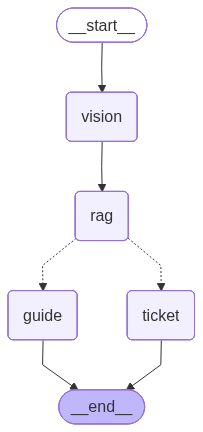

In [15]:
# 그래프 시각화
from IPython.display import display, Image as IPImage

display(IPImage(app.get_graph().draw_mermaid_png()))

---
## 🚀 Section 5: End-to-End 실행 테스트

4가지 테스트 이미지를 모두 실행하여 각 경로(안내/티켓)가 올바르게 분기되는지 확인합니다.

In [ ]:
TEST_IMAGES = [
    "/home/user/MultiAgents/Day_3/Projects/hightemp.png",   # → 안내 경로 예상 (guide)
    "/home/user/MultiAgents/Day_3/Projects/nosim.jpg",      # → 안내 경로 예상 (guide)
    "/home/user/MultiAgents/Day_3/Projects/nowifi.png",     # → 안내 경로 예상 (guide)
    "/home/user/MultiAgents/Day_3/Projects/nospace.jpg",    # → 티켓 경로 예상 (ticket)
]

for img_path in TEST_IMAGES:
    img_name = img_path.split("/")[-1]
    print("=" * 60)
    print(f"🖼️  테스트 이미지: {img_name}")
    print("=" * 60)

    result = app.invoke({
        "image_url":        img_path,
        "error_symptom":    "",
        "retrieved_manual": "",
        "rag_score":        0.0,
        "final_answer":     "",
    })

    print(f"🔍 [Node 1] VLM 추출 증상:")
    print(f"   {result['error_symptom'][:150]}")
    print(f"\n📊 [Node 2] RAG 점수: {result['rag_score']:.4f}  →  {'안내 경로 ✅' if result['rag_score'] <= SCORE_THRESHOLD else '티켓 경로 🎫'}")
    print(f"\n💬 [Node 3] 최종 출력:")
    print(f"   {result['final_answer'][:300]}")
    print()

In [ ]:
# 위 5번 파트까지 진행해오면서 4장 이미지에 대해 루프 돌때 GPU 점유 상황입니다.
# 즉, Node1에서 2B VLM 쓰고 Node3에서 E2B 쓸 경우 VRAM 안전하고 여유 있습니다.
# 만약 CUDA Out of Memory Error를 겪을 경우 프로젝트 FAQ 안내를 따라주세요.

# +-----------------------------------------------------------------------------------------+
# | NVIDIA-SMI 550.90.07              Driver Version: 550.90.07      CUDA Version: 12.4     |
# |-----------------------------------------+------------------------+----------------------+
# | GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
# | Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
# |                                         |                        |               MIG M. |
# |=========================================+========================+======================|
# |   0  Tesla T4                       On  |   00000000:00:04.0 Off |                    0 |
# | N/A   75C    P0             32W /   70W |   12045MiB /  15360MiB |      0%      Default |
# |                                         |                        |                  N/A |
# +-----------------------------------------+------------------------+----------------------+

# +-----------------------------------------------------------------------------------------+
# | Processes:                                                                              |
# |  GPU   GI   CI        PID   Type   Process name                              GPU Memory |
# |        ID   ID                                                               Usage      |
# |=========================================================================================|
# |    0   N/A  N/A   1681562      C   /opt/conda/bin/python                        6334MiB |
# |    0   N/A  N/A   1683383      C   /usr/local/bin/ollama                        5708MiB |
# +-----------------------------------------------------------------------------------------+

---
## 🔥 Extension Problems (비채점 — 도전 문제)

아래 문제들은 채점에 포함되지 않습니다.
시간이 남거나 더 깊이 파고싶은 분들을 위한 문제입니다.

### Extension 1: Human-in-the-Loop 티켓 승인

LangGraph의 `interrupt` 기능을 사용하면 그래프 실행 중간에 사람의 개입을 받을 수 있습니다.

**목표:** `node_ticket` 실행 후 사람이 티켓 내용을 검토·수정한 뒤 승인하면 최종 저장되도록 구현하세요.

```python
from langgraph.types import interrupt

def node_ticket_review(state: TroubleshootingState) -> dict:
    ticket = generate_ticket(state["error_symptom"])
    
    # 사람에게 티켓 내용을 보여주고 수정 받음
    reviewed = interrupt({
        "message": "티켓 내용을 검토하세요. 수정이 필요하면 딕셔너리로 반환하세요.",
        "ticket": ticket
    })
    
    final_ticket = reviewed if isinstance(reviewed, dict) else ticket
    return {"final_answer": json.dumps(final_ticket, ensure_ascii=False, indent=2)}
```

힌트:
- `workflow.compile(checkpointer=MemorySaver())` 로 체크포인터를 설정해야 합니다
- `app.invoke(..., config={"configurable": {"thread_id": "1"}})` 로 실행하세요
- `interrupt` 발생 후 `app.invoke(Command(resume=수정된_티켓), config=...)` 로 재개합니다

In [17]:
# Extension 1 구현 공간
# =====================================================================
# Extension 1: Human-in-the-Loop 티켓 승인 (정답 코드)
# =====================================================================
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import MemorySaver

# 1. 인터럽트를 발생시키는 리뷰용 노드 정의
def node_ticket_review(state: TroubleshootingState) -> dict:
    print("  [Node 3b] LLM: CS 티켓 생성 중 (검토 대기)...")
    ticket = generate_ticket(state["error_symptom"])
    
    # 사람에게 티켓 내용을 보여주고 실행을 일시 정지 (Interrupt)
    reviewed = interrupt({
        "message": "티켓 내용을 검토하세요. 승인하려면 그대로 반환하고, 수정하려면 딕셔너리를 변경하여 반환하세요.",
        "ticket": ticket
    })
    
    # 재개(Resume)될 때 들어온 값이 딕셔너리면 수정본으로 간주, 아니면 원본 사용
    final_ticket = reviewed if isinstance(reviewed, dict) else ticket
    return {"final_answer": f"[티켓] {json.dumps(final_ticket, ensure_ascii=False, indent=2)}"}

# 2. 새로운 노드로 워크플로우 덮어쓰기 및 컴파일
workflow_hitl = StateGraph(TroubleshootingState)
workflow_hitl.add_node("vision", node_vision)
workflow_hitl.add_node("rag", node_rag)
workflow_hitl.add_node("guide", node_guide)
workflow_hitl.add_node("ticket", node_ticket_review) # 변경된 노드 연결

workflow_hitl.add_edge(START, "vision")
workflow_hitl.add_edge("vision", "rag")
workflow_hitl.add_conditional_edges("rag", route_by_score, {"guide": "guide", "ticket": "ticket"})
workflow_hitl.add_edge("guide", END)
workflow_hitl.add_edge("ticket", END)

# 체크포인터(MemorySaver)를 반드시 추가해야 interrupt가 작동합니다.
memory = MemorySaver()
app_hitl = workflow_hitl.compile(checkpointer=memory)

# 3. 동작 확인 (스레드 ID 필수)
config = {"configurable": {"thread_id": "ticket_thread_001"}}
test_input = {
    "image_url": "/home/user/MultiAgents/Day_3/Projects/nospace.jpg", 
    "error_symptom": "", "retrieved_manual": "", "rag_score": 0.0, "final_answer": ""
}

print("▶️ 1차 실행 (티켓 검토에서 일시 정지됨):")
result_paused = app_hitl.invoke(test_input, config=config)

# 상태 확인
state = app_hitl.get_state(config)
pending_interrupt = state.tasks[0].interrupts[0].value
print("\n[대기 중인 티켓 내용]:", pending_interrupt["ticket"]["summary"])

# 4. 리뷰 완료 및 워크플로우 재개 (Resume)
print("\n▶️ 2차 실행 (검토 완료 및 재개):")
approved_ticket = pending_interrupt["ticket"]
approved_ticket["recommended_action"] = "관리자가 직접 수정한 권장 조치사항"

result_final = app_hitl.invoke(Command(resume=approved_ticket), config=config)
print("\n최종 출력:\n", result_final["final_answer"])

### Extension 2: ChatOllama 인스턴스를 통한 Thinking Mode 관찰

모델 버전과 Ollama 버전에 따라 추론 모드를 켜는 방법이 다릅니다.
`<think> 태그 prefill`,
`reasoning=True`,
`think=True`
3가지 방법에 대해 조사 후, ChatOllama 인스턴스에 적절한 파라미터를 입력으로 주거나,
프롬프트에 구분자를 주입하여 thinking mode를 활성화시켜보세요.


### thinking 모드 주의사항

thinking 모드가 활성화되어 있으면:
- `<think>...</think>` 블록이 출력의 대부분을 차지
- `num_predict` 기본값(128)이 작으면 실제 답변 없이 잘릴 수 있음
- **반드시 `think=False`로 비활성화하거나 `num_predict`를 충분히 크게 설정하세요**

**목표:** thinking 모드를 켜고 티켓 생성 시 추론 과정이 어떻게 다른지 관찰하세요.


In [18]:
# Extension 2 구현 공간
# =====================================================================
# Extension 2: On-device LLM Thinking Mode 활성화 3단계 (정답 코드)
# =====================================================================

# Gemma3n은 thinking 모델이 아닙니다.
# 그럼 Gemma3n은 think 기능을 아예 못 쓰냐? -> 그렇지 않습니다. 단지 Ollama 단에서 think라는 파라미터를 통해 켤 수 없을 뿐입니다.
# 모델 구조와 LangChain 통합 버전에 따라 Thinking을 활성화하는 진입점(Entry Point)이 다릅니다.
# 각 레벨에 따라 <think> 태그 prefill 방식, reasoning 파라미터 활용 방식, think 파라미터 활용 방식이 있습니다.

from langchain_core.messages import HumanMessage, AIMessage

# ---------------------------------------------------------
# Level 1. [Lowest Level] Assistant Prefill 기법 (Gemma 3n)
# ---------------------------------------------------------
# Gemma 3n처럼 네이티브 reasoning 파라미터를 미지원하는 모델은, 
# 랭체인이 프롬프트 마지막에 강제로 <think>\n 태그를 주입하여 추론을 유도해야 합니다.
llm_gemma3n = ChatOllama(model="gemma3n:e2b", temperature=0.1)

messages_prefill = [
    HumanMessage(content="저장공간 부족 에러에 대해 CS 티켓용 원인을 1문장으로 생각해봐."),
    AIMessage(content="<think>\n")  # 모델이 여기서부터 말을 이어가도록 강제함
]
response_prefill = llm_gemma3n.invoke(messages_prefill)
print("1. [Gemma 3n Prefill 출력]\n", response_prefill.content, "\n")


# ---------------------------------------------------------
# Level 2. [Higher Level] 'reasoning' 파라미터 (Qwen 3.5:2b)
# ---------------------------------------------------------
# 랭체인 공식 통합 패키지(langchain-ollama)의 표준 파라미터는 `reasoning` 입니다.
# 이 파라미터를 지원하는 모델(예: qwen3.5:2b, DeepSeek-R1 등)에 넘기면,
# 랭체인이 내부적으로 <think> 태그를 발라내어 'additional_kwargs'에 분리해 줍니다.
try:
    llm_qwen = ChatOllama(model="qwen3.5:2b", temperature=0.1, reasoning=True)
    response_qwen = llm_qwen.invoke("저장공간 부족 에러에 대해 CS 티켓용 원인을 1문장으로 생각해봐.")
    
    print("2. [Qwen 3.5:2b 추론 과정 분리]\n", response_qwen.additional_kwargs.get("reasoning_content", "없음"))
    print("\n[Qwen 3.5:2b 최종 답변]\n", response_qwen.content, "\n")
except Exception as e:
    print("2. [Qwen 3.5:2b] 모델이 설치되어 있지 않거나 reasoning 파라미터를 지원하지 않습니다.\n")


# 주의! 클라우드 환경의 Ollama는 구버전이라 Gemma 4 pull이 안 됩니다.
# 3일차 gemma4_vision_colab.ipynb의 내용을 아래 코드 참고하여 수정 후 사용해주세요.
# gemma4_vision_colab.ipynb는 복습자료 구글드라이브 폴더에 있습니다 -> 코랩 환경에서 실행해주세요
# ---------------------------------------------------------
# Level 3. [Future Level] 'think' 파라미터 (Gemma 4 등)
# ---------------------------------------------------------
# 특정 최신 아키텍처(Gemma 4 등)나 커스텀 인터페이스에서는 
# 직관적인 'think=True' 파라미터를 직접 API 레벨에서 받을 수 있도록 진화하고 있습니다.
try:
    llm_gemma4 = ChatOllama(model="gemma4:e2b", temperature=0.1, think=True)
    # response_gemma4 = llm_gemma4.invoke("저장공간 부족 에러에 대해 CS 티켓용 원인을 생각해봐.")
    print("3. [Gemma 4] think 파라미터 통과 확인 (모델 다운로드 완료 시 실행 가능)")
except Exception as e:
    print("3. [Gemma 4] 환경에 아직 Gemma 4가 없습니다.")

### Extension 3: 티켓 중복 감지

같은 증상의 티켓이 반복 접수되는 경우 중복 감지가 필요합니다.

**목표:** 새로운 티켓 증상을 기존 티켓 DB의 증상들과 임베딩 유사도로 비교하여,
유사 티켓이 존재하면 새 티켓 생성 대신 기존 티켓 번호를 반환하도록 구현하세요.

힌트:
- 별도의 `Chroma` 컬렉션에 티켓 증상을 저장하세요
- `similarity_search_with_score` 로 유사 티켓을 검색하세요
- 유사도 임계값 이하이면 중복으로 처리하세요

In [19]:
# Extension 3 구현 공간
# =====================================================================
# Extension 3: 티켓 중복 감지 체인 (정답 코드)
# =====================================================================
from langchain_chroma import Chroma
from langchain_core.documents import Document

# 1. 중복 감지용 티켓 벡터스토어 (기존 RAG와 별도의 Collection 사용)
ticket_vector_store = Chroma(
    collection_name="samsung_cs_tickets_db",
    embedding_function=vector_store.embeddings # Section 0에서 만든 임베딩 재사용
)
ticket_vector_store.delete_collection() # 테스트를 위해 초기화
ticket_vector_store = Chroma(collection_name="samsung_cs_tickets_db", embedding_function=vector_store.embeddings)

# 2. 과거 접수된 샘플 티켓 1개 강제 주입
sample_symptom = "저장공간이 꽉 차서 더 이상 앱을 설치하거나 사진을 저장할 수 없어요"
ticket_vector_store.add_documents([
    Document(page_content=sample_symptom, metadata={"ticket_id": "TKT-PREV99"})
])


def generate_ticket_with_dedup(symptom: str) -> dict:
    """새 증상을 기존 DB와 비교하여 중복을 감지하거나 새 티켓을 생성합니다."""
    
    # 매뉴얼 검색(1.2)보다 훨씬 빡빡한 임계값 설정 (거의 동일한 에러만 중복 처리)
    DEDUP_THRESHOLD = 0.6 
    
    print("  [중복 체크] 기존 티켓 검색 중...")
    results = ticket_vector_store.similarity_search_with_score(symptom, k=1)
    
    if results:
        doc, score = results[0]
        if score <= DEDUP_THRESHOLD:
            print(f"  🚨 중복 티켓 감지됨 (L2 점수: {score:.4f}). 기존 티켓 번호로 병합합니다.")
            return {
                "priority": "INFO",
                "team": "CS팀",
                "summary": "중복 접수건",
                "recommended_action": f"기존 티켓({doc.metadata['ticket_id']}) 참조",
                "ticket_id": doc.metadata["ticket_id"],
                "symptom": symptom
            }
    
    # 중복이 아니면 원본 함수로 새 티켓 생성
    print("  ✅ 새로운 이슈. 신규 티켓을 생성하고 DB에 등록합니다.")
    new_ticket = generate_ticket(symptom) 
    
    # 새 티켓을 DB에 저장하여 추후 중복 감지에 활용
    ticket_vector_store.add_documents([
        Document(page_content=symptom, metadata={"ticket_id": new_ticket["ticket_id"]})
    ])
    return new_ticket

# --- 테스트 실행 ---
print("==== 1차 접수 (유사한 에러 입력) ====")
ticket_result_1 = generate_ticket_with_dedup("저장 공간이 너무 부족해서 아무것도 안돼요")
print("반환된 티켓 ID:", ticket_result_1["ticket_id"])

print("\n==== 2차 접수 (완전히 새로운 에러 입력) ====")
ticket_result_2 = generate_ticket_with_dedup("화면이 갑자기 파랗게 변하고 터치가 안 먹혀요")
print("반환된 티켓 ID:", ticket_result_2["ticket_id"])

### Extension 4: Ablation Study


**목표:** 구현하신 시스템이 baseline 대비 어느 정도 성능이 좋은지
측정하기 위한 실험을 설계하세요.

**질문:** 프로젝트에 쓰인 qwen3-vl이나 gemma3n보다 최신이면서 멀티모달 기능까지 갖춘

gemma4를 *잘 프롬프팅*하기만 하면 굳이 멀티 에이전트 시스템, RAG, 랭그래프, 분기 로직 등이 필요없진 않을까요?

위 궁금증을 해소하기 위해서 gemma4만을 사용한 baseline을 구축하세요.

baseline에는 오직 이미지와 텍스트 프롬프트만 입력으로 줄 수 있으며, 출력물의 내용과 형식은 프로젝트와 같아야 합니다.

적절한 프롬프트를 작성하고, llama.cpp 서버에 실려있는 gemma4를 통해 정성적인 성능을 관찰해보세요.

주어진 4장의 사진과 고객 매뉴얼 샘플에 대해서 만약 gemma4가 프로젝트 구현체보다 성능이 좋다 해도,

프로젝트에 적용된 기술들의 타당성을 검증할 방법은 있습니다. 어떤 측면에서일까요?

------------------------------------------------------------------

참고: Ablation?

Ablation이라 함은 여러 기술의 집약체인 시스템에서,

각 기술이 시스템 전반의 성능에 얼마나 기여하고 있는지 알아보기 위해

구성 요소를 하나씩 분리해보는 조사 방법을 가리킵니다.

예를 들어 지금의 CS 티켓팅 & 에스컬레이션 멀티에이전트 시스템에서

ablation의 대상이 되는 컴포넌트 기술은 다음과 같이 정리해볼 수 있습니다:

A. vision 노드와 안내 노드를 분리했다는 점

B. RAG를 적용했다는 점

C. 브랜칭 함수의 설계와 랭그래프 구성을 통해, 자동 안내 메시지를 출력할지 티켓을 생성할지 분기했다는 점

본래 의미에 충실한 정밀 ablation이라면 각각 하나씩 제거해가면서 (또는 각 컴포넌트의 baseline으로 대체해가면서)

그에 따른 성능 저하를 추적하는게 옳습니다.

시간 상 제약이 있는만큼, "**모든** 기술을 **제거**한 좀 더 최신 멀티모달 모델"과

"프로젝트를 통해 구현하신 시스템"의 대결 구도로 ablation을 단순화해서 생각해봅시다.



In [ ]:
# Extension 4: Ablation — Single-Prompt Gemma 4 Baseline
# =====================================================================
# 본 셀은 프로젝트의 멀티에이전트 + RAG + LangGraph + 분기 로직을 모두 제거하고,
# "이미지 한 장 + 텍스트 프롬프트 한 개" 만으로 동작하는 단일 호출 베이스라인을
# 구축합니다. 모델은 docker 로 띄워둔 llama.cpp 서버의 Gemma 4
# 를 사용합니다.

import base64, mimetypes
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

# ─── (1) Gemma 4 클라이언트 (llama.cpp 서버 = OpenAI-compatible) ────────────────
# 사전 조건: 별도 터미널에서 `bash start_llama_server.sh` 가 떠 있어야 함.
SERVER_HOST = "127.0.0.1"
SERVER_PORT = 8181

gemma4 = ChatOpenAI(
    model="gemma",                                  # llama-server --alias 와 동일
    base_url=f"http://{SERVER_HOST}:{SERVER_PORT}/v1",
    api_key="not-needed",                           # 로컬 서버이므로 무의미값
    temperature=0.1,
    max_tokens=512,
)

# ─── (2) 메가 프롬프트 ───────────────────────────────────────────────────────
# 파이프라인의 모든 단계 (증상 추출 → 매뉴얼 매칭 → 분기 → 형식별 생성) 를
# 프롬프트 한 개로 압축합니다. RAG 가 사라졌으므로 매뉴얼 전문을 직접 주입.
#
# DEVICE_MANUAL 은 Problem 2 셀에서 정의된 전역 변수를 그대로 재사용.

BASELINE_PROMPT = f"""당신은 삼성전자 CS(고객서비스) 트리아지 어시스턴트입니다.
입력으로 (1) 스마트폰 에러 화면 이미지와 (2) 아래 CS 매뉴얼 전문이 주어집니다.
당신의 임무는 멀티 단계 파이프라인 없이 한 번의 응답으로 최종 출력을 생성하는 것입니다.

# 내부 수행 절차 (출력하지 말 것)
1. 이미지를 보고 화면에 나타난 에러 증상을 파악합니다.
2. [CS 매뉴얼] 전문에서 해당 증상에 부합하는 항목이 있는지 확인합니다.
3. 분기 규칙:
   - 매뉴얼에 부합하는 항목이 있음  →  [안내] 형식으로 응답
   - 매뉴얼에 부합하는 항목이 없음  →  [티켓] 형식으로 응답

# [CS 매뉴얼]
{DEVICE_MANUAL}

# 출력 형식

(A) 매뉴얼 항목이 있을 경우 — 정확히 다음 형식만 출력:
[안내] <친절하고 명확한 해결 안내. 한국어, 3줄 이내, 매뉴얼 내용을 기반으로 작성>

(B) 매뉴얼 항목이 없을 경우 — 정확히 다음 형식만 출력:
[티켓] {{"priority": "HIGH 또는 MEDIUM 또는 LOW", "team": "하드웨어팀 또는 소프트웨어팀 또는 네트워크팀 또는 스토리지팀", "summary": "30자 이내 증상 요약", "recommended_action": "50자 이내 1차 조치"}}

# 매우 중요한 규칙
- 위 두 가지 형식 중 정확히 하나만 출력합니다. 다른 어떤 텍스트도 앞뒤에 추가하지 마세요.
- 사고 과정, 단계별 추론, 인사말, 결과 부연 설명을 출력하지 마세요.
- [티켓]을 출력할 때 JSON 은 한 줄로 작성하며, 위에 명시된 4개 키 외 다른 키를 추가하지 마세요.
- [안내]에는 매뉴얼에 명시되지 않은 내용을 포함하지 마세요. 매뉴얼에 없는 내용을 안내해야 한다면, 그것은 [티켓]을 출력해야 한다는 신호입니다.
- 답변은 반드시 한국어로 작성하세요.
"""

# ─── (3) 이미지를 OAI 호환 data URL 로 인코딩 ────────────────────────────────
def _image_to_data_url(path: str) -> str:
    mime = mimetypes.guess_type(path)[0] or "image/png"
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    return f"data:{mime};base64,{b64}"


# ─── (4) 단일 호출 베이스라인 함수 ───────────────────────────────────────────
def baseline_one_shot(image_path: str) -> str:
    """이미지 + 메가 프롬프트 → Gemma 4 한 번 호출 → 최종 출력."""
    user_msg = HumanMessage(content=[
        {"type": "image_url", "image_url": {"url": _image_to_data_url(image_path)}},
        {"type": "text",      "text":      BASELINE_PROMPT},
    ])
    response = gemma4.invoke([user_msg])
    return response.content.strip()


# ─── (5) 동일 4장 테스트 이미지에 대해 베이스라인 실행 ───────────────────────
EXPECTED_BRANCH = {
    "hightemp.png": "guide",   # TEMP-01  → 매뉴얼 있음
    "nosim.jpg":    "guide",   # SIM-01   → 매뉴얼 있음
    "nowifi.png":   "guide",   # NET-03   → 매뉴얼 있음
    "nospace.jpg":  "ticket",  # 매뉴얼 미등재 → 티켓 경로
}

print("=" * 70)
print("🔬 ABLATION BASELINE: Gemma 4 단일 호출 (RAG/LangGraph/분기 모두 제거)")
print("=" * 70)

for img_path in TEST_IMAGES:
    img_name = img_path.split("/")[-1]
    expected = EXPECTED_BRANCH.get(img_name, "?")

    print(f"\n🖼️  {img_name}   (expected: {expected})")
    print("-" * 70)

    output = baseline_one_shot(img_path)
    # 베이스라인이 어떤 경로를 "스스로" 선택했는지 prefix 로 확인
    chosen = "guide"  if output.startswith("[안내]") else \
             "ticket" if output.startswith("[티켓]") else "malformed"
    match  = "✅" if chosen == expected else "❌"

    print(f"   선택 경로: {chosen}  {match}")
    print(f"   출력:")
    for line in output.splitlines():
        print(f"     {line}")

# ─── (6) 관찰 포인트 — 정성적 결과를 보고 채워야 할 메타 질문 ────────────────
# 이 베이스라인이 4장 케이스에서 잘 작동하더라도, 프로젝트 구현체가 가지는
# 다음 측면은 단일 호출로는 검증되지 않거나 보장되지 않습니다:
#
#   1) 결정론적 라우팅
#      - 본 구현체: rag_score vs SCORE_THRESHOLD 의 결정론적 비교.
#      - 베이스라인: LLM 이 라우팅까지 담당 → 같은 입력에도 분기가 흔들릴 수 있음.
#
#   2) 그라운딩 / 환각 통제
#      - 본 구현체: [안내] 텍스트가 RAG 가 가져온 매뉴얼 청크에서만 도출됨 (출처 추적 가능).
#      - 베이스라인: 매뉴얼 외 지식으로 그럴듯한 거짓 안내를 생성할 위험. 특히 nospace 케이스에서
#        매뉴얼에 없는데도 "있는 척" 안내해버리면 검증이 어렵습니다.
#
#   3) 확장성 (매뉴얼 규모)
#      - 본 구현체: 매뉴얼이 100배, 1000배 커져도 RAG 가 top-k 만 가져오므로 컨텍스트 일정.
#      - 베이스라인: 매뉴얼 전문이 프롬프트에 들어가므로 토큰/지연/비용이 매뉴얼 크기에 비례.
#
#   4) 모듈성 / 교체 비용
#      - 본 구현체: VLM, 임베딩, LLM, 라우팅 함수 각각 독립 교체 가능.
#      - 베이스라인: 한 모델에 모든 책임을 묶음 — 한 곳만 바꿔도 전체 거동이 흔들림.
#
#   5) 감사 가능성 / 디버깅
#      - 본 구현체: 각 노드 출력이 State 에 남아 있어 "어디서 틀렸는지" 추적 가능.
#      - 베이스라인: 단일 호출의 내부 추론은 블랙박스.
#
# 따라서 정성적 4장 비교에서 베이스라인이 비등하거나 더 좋아 보여도, 위 (1)~(5) 차원은
# 그 4장 대결로는 측정되지 않습니다. 본격적인 ablation 이라면 각 컴포넌트를 하나씩만
# 제거/대체해가며 위 5개 차원을 정량 측정해야 합니다 — Extension 4 의 본래 정신.